# Testing new objective function

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
z_slice_mosh = 25
bins_mosh = 85
dose_grid_half_mosh = 2.5
lattice_mosh = dose_grid_half_mosh*2/bins_mosh
source_transZ_mosh = -0.5
source_plane_mosh = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, dose_grid_half_mosh*2/bins_mosh)

In [7]:
applicator_rad = 0.3
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

In [5]:
dose = 20 # Gy
dose_point = (0.0, 0.5) # cm - in center of roi

In [8]:
mosh = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"

norm_energy, voxel = extract_norm_energy(mosh, source_plane_mosh, 2, dose_point, bins_mosh, lattice_mosh)

Xm, Ym, energy, __ = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy, dose=dose, zero_source=True, std_dev=False)

In [11]:
error = 0.025 # cm - extracting energy from voxels
delta = 0.05 # cm - offset from applicator edge
theta = pi/2

lin_mosh, const_rad_mosh = energy_along_theta(mosh, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, z_slice_mosh, err=error, radius=applicator_rad + delta,
                                             scale=True, norm_energy=norm_energy, dose=dose)

<ErrorbarContainer object of 3 artists>

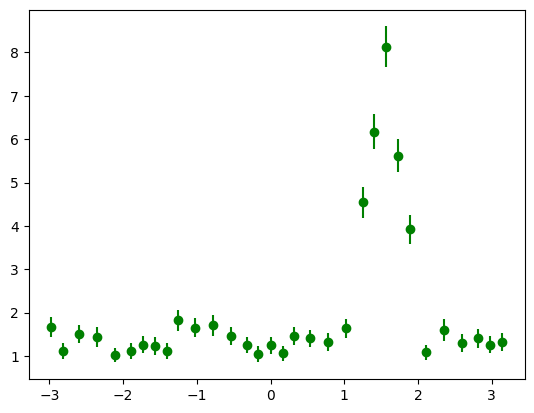

In [12]:
# Sanity check - plot energy at constant radius
thetam, ym, std_dev_sum_theta_m, __, __ = plotter_1D(const_rad_mosh, ind_var=1, std_dev=True, num_Hx=1e7)

fig1, ax1 = plt.subplots()
ax1.errorbar(thetam, ym, yerr=std_dev_sum_theta_m, fmt="go")

New objective function:

$$ f(E, E') = \left [1 - \left ( \sum_{i} | E_i - E'_{i} |^2 \right ) \right ]^{-1} $$

In [86]:
# There are designed to be used with normalized energy values
def log_obj_func(energy1, energy2):
    diff = np.sum(np.abs(energy1 - energy2)**2)
    return 1/(1 - np.log(diff))

def noLog_obj_func(energy1, energy2):
    diff = np.sum(np.abs(energy1 - energy2)**2)
    #return 1/(1 - diff)
    return diff

In [61]:
# Randomize energy for comparison
def random_by_point(energy):
    rand = np.empty(np.shape(energy))
    it = np.nditer(energy, flags=['multi_index'])
    for x in it:
        b = x + x/2
        a = x - x/2
        offset = (b - a)*np.random.rand() + a
        rand[it.multi_index] = offset
    return rand

In [62]:
rand_mosh = random_by_point(ym)

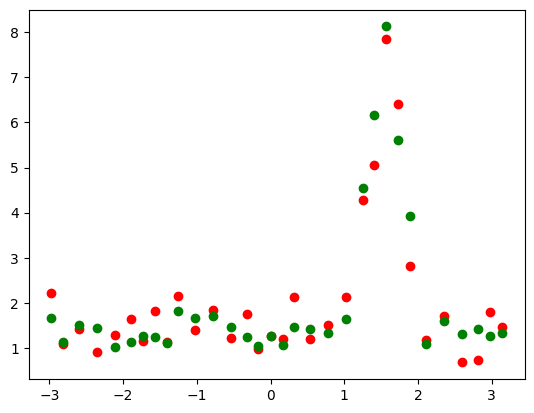

In [63]:
fig2, ax2 = plt.subplots()
ax2.scatter(thetam, rand_mosh, color="red")
ax2.scatter(thetam, ym, color="green")

In [92]:
# Constant offset - to test convergence of objective function
offset = np.arange(0, 3, 0.2)

obj_values = np.array([])
for x in offset:
    energy_off = ym + x
    print(x, noLog_obj_func(ym, energy_off))
    obj_values = np.append(obj_values, noLog_obj_func(ym, energy_off))

0.0 0.0
0.2 1.2799999999999994
0.4 5.120000000000001
0.6000000000000001 11.520000000000003
0.8 20.480000000000004
1.0 32.0
1.2000000000000002 46.08000000000001
1.4000000000000001 62.72000000000001
1.6 81.92000000000002
1.8 103.68
2.0 128.0
2.2 154.88000000000005
2.4000000000000004 184.32000000000005
2.6 216.32
2.8000000000000003 250.88000000000005


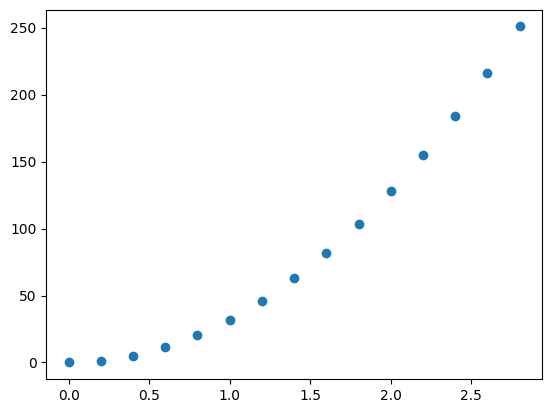

In [93]:
fig3, ax3 = plt.subplots()
ax3.scatter(offset, obj_values)